# ML Practical session 5: Feature selection (filter & wrapper methods)

Dataset: Breast Cancer Wisconsin (Diagnostic), 569 samples, 30 features.
Target: 0 = malignant, 1 = benign. 

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


# scaler + logistic regression in one pipeline so the scaler only ever sees training data
def make_model():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000)),
    ])


# returns accuracy and F1 for the malignant class (label 0)
def evaluate(y_true, y_pred):
    return accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, pos_label=0)

---
## Part A – Data inspection and baseline
### A.1 Loading and checking the data

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame
X = data.data
y = data.target

print("Full table:", df.shape)
print("X:", X.shape)
print("\nTypes:\n", X.dtypes.value_counts())
print("\nMissing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

Full table: (569, 31)
X: (569, 30)

Types:
 float64    30
Name: count, dtype: int64

Missing values: 0
Duplicated rows: 0


In [3]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


569 rows, 30 features, all floats. No missing values and no duplicates, so nothing to clean.
The scales are all over the place though (mean area goes up to 2500, fractal dimension is around 0.06),
so we'll definitely need to standardise before using logistic regression.

### A.2 Target distribution + dummy baseline

           class  count  proportion
0  malignant (0)    212       0.373
1     benign (1)    357       0.627


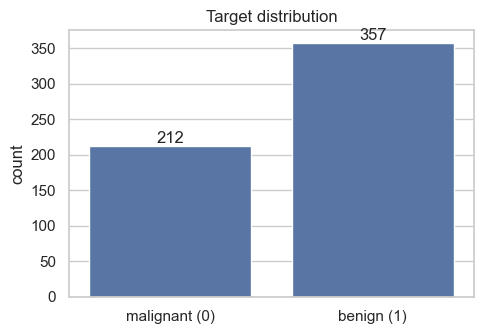

In [4]:
counts = y.value_counts().sort_index()
print(pd.DataFrame({"class": ["malignant (0)", "benign (1)"],
                    "count": counts.values,
                    "proportion": (counts / len(y)).round(3).values}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x=y.map({0: "malignant (0)", 1: "benign (1)"}), ax=ax,
              order=["malignant (0)", "benign (1)"])
ax.set_xlabel("")
ax.set_title("Target distribution")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

### A.3 Train/test split (70/30, stratified) and scaling
Split once here and reuse the same split for the rest of the session.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Benign proportion -> train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

# scaler fitted on train only, then applied to test
scaler = StandardScaler().fit(X_train)
X_train_sc = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

Train: (398, 30)  Test: (171, 30)
Benign proportion -> train: 0.628, test: 0.626


In [6]:
# dummy baseline: always predicts the majority class (benign)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_acc, dummy_f1 = evaluate(y_test, dummy.predict(X_test))
print(f"Dummy -> test accuracy: {dummy_acc:.4f}, F1 (malignant): {dummy_f1:.4f}")

Dummy -> test accuracy: 0.6257, F1 (malignant): 0.0000


The dummy gets about 63% accuracy just by saying "benign" every time, since 63% of the patients are benign.
But its F1 is 0 because it never finds a single malignant case. So accuracy on its own is a bit misleading here,
and any proper model needs to be well above 63%.

### A.4 Logistic regression on all 30 features (our reference)

In [7]:
baseline = make_model()

t0 = time.perf_counter()
baseline.fit(X_train, y_train)
baseline_time = time.perf_counter() - t0

train_acc, train_f1 = evaluate(y_train, baseline.predict(X_train))
test_acc, test_f1 = evaluate(y_test, baseline.predict(X_test))
cv_scores = cross_val_score(make_model(), X_train, y_train, cv=cv, scoring="accuracy")

baseline_row = pd.DataFrame([{
    "Method": "Baseline (all features)", "Nb features": X.shape[1],
    "Train acc": train_acc, "Train F1": train_f1,
    "CV acc": f"{cv_scores.mean():.4f} ± {cv_scores.std():.4f}",
    "Test acc": test_acc, "Test F1": test_f1, "Time (s)": baseline_time,
}])
baseline_row.round(4)

,Method,Nb features,Train acc,Train F1,CV acc,Test acc,Test F1,Time (s)
0,Baseline (all features),30,0.9874,0.9829,0.9824 ± 0.0189,0.9883,0.9844,0.0172


Test accuracy is 98.8% (only 2 mistakes out of 171) and the F1 is 0.984. Train and test are basically the same,
so it's not overfitting. This is the score to beat, or at least match, with fewer features.

### A.5 Correlation matrix

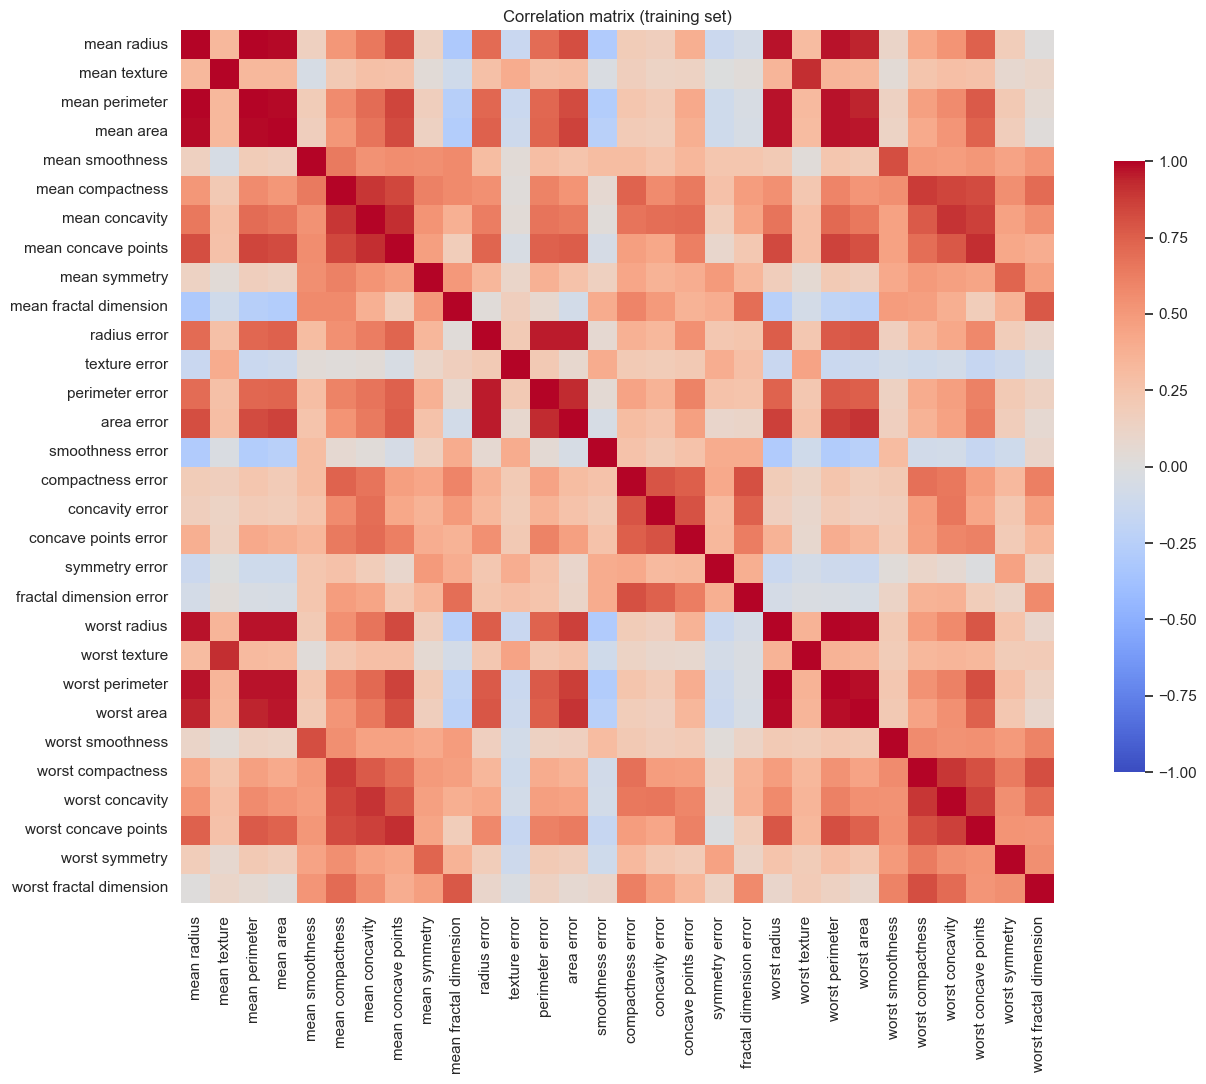

In [8]:
corr = X_train.corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation matrix (training set)")
plt.tight_layout()
plt.show()

In [9]:
# pairs with |r| > 0.90
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = (upper.stack()
              .loc[lambda s: s > 0.90]
              .sort_values(ascending=False)
              .rename("|r|")
              .reset_index()
              .rename(columns={"level_0": "feature 1", "level_1": "feature 2"}))
print(len(pairs), "pairs with |r| > 0.90\n")
print(pairs.round(3).to_string(index=False))

23 pairs with |r| > 0.90

          feature 1            feature 2   |r|
        mean radius       mean perimeter 0.998
       worst radius      worst perimeter 0.993
        mean radius            mean area 0.991
     mean perimeter            mean area 0.989
       worst radius           worst area 0.986
    worst perimeter           worst area 0.978
     mean perimeter      worst perimeter 0.975
          mean area         worst radius 0.974
        mean radius         worst radius 0.974
     mean perimeter         worst radius 0.974
          mean area      worst perimeter 0.970
        mean radius      worst perimeter 0.970
          mean area           worst area 0.964
       radius error      perimeter error 0.960
       radius error           area error 0.954
        mean radius           worst area 0.945
     mean perimeter           worst area 0.944
    perimeter error           area error 0.925
mean concave points worst concave points 0.919
       mean texture        worst t

In [10]:
# put the correlated features into groups (if A~B and B~C then A, B, C go in the same group)
def correlated_groups(corr, threshold):
    cols = list(corr.columns)
    seen, groups = set(), []
    for start in cols:
        if start in seen:
            continue
        stack, group = [start], set()
        while stack:
            f = stack.pop()
            if f in group:
                continue
            group.add(f)
            stack += [g for g in cols if g != f and abs(corr.loc[f, g]) > threshold]
        seen |= group
        if len(group) > 1:
            groups.append(sorted(group))
    return groups


for i, g in enumerate(correlated_groups(corr, 0.90), 1):
    print(f"Group {i} ({len(g)} features): {', '.join(g)}")

Group 1 (9 features): area error, mean area, mean perimeter, mean radius, perimeter error, radius error, worst area, worst perimeter, worst radius
Group 2 (2 features): mean texture, worst texture
Group 3 (4 features): mean concave points, mean concavity, worst concave points, worst concavity


There are 23 pairs above 0.90, and they fall into 3 groups:
- **Size:** radius, perimeter and area (mean, worst and the error versions). Mean radius vs mean perimeter is 0.998,
  which makes sense since perimeter is basically 2πr.
- **Texture:** mean texture and worst texture.
- **Concavity:** mean/worst concavity and mean/worst concave points.

So realistically one feature per group would probably be enough.

**Why this dataset is a good fit for feature selection:**
- Loads of redundancy. Radius, perimeter and area are pretty much the same info, and it's repeated for mean/error/worst.
- The full model already gets ~99%, so the point isn't to boost accuracy, it's to see how many features we can drop
  without losing anything (simpler model, easier to explain to a doctor).
- Only 398 training samples for 30 features, and with that many correlated features the coefficients
  can get quite unstable, so cutting some down should help.